In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# 02. Sales trends over time

## What this notebook does, in plain words

A trend is a pattern over time. This notebook groups the clean sales by month, by weekday, and by hour of day, so we can see when the shop is busy and when it is quiet.

## One warning before the charts

December 2011 is a partial month. The data stop on 9 December 2011, so its bar looks low for a simple reason: most of the month is missing. Do not read it as a collapse in demand. Complete months run from December 2010 to November 2011.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 120
ROOT = Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'online_retail.csv'
print('Charts folder:', CHARTS)
print('Data folder:', DATA)


Charts folder: /home/hatch/workspace/repo-builds/datanalytics-project/charts
Data folder: /home/hatch/workspace/repo-builds/datanalytics-project/data/processed


In [3]:
df = pd.read_csv(DATA / 'clean_transactions.csv', parse_dates=['InvoiceDate'])
print('Rows:', len(df), 'Revenue, pounds:', round(df['Revenue'].sum(), 2))
monthly = df.groupby(df['InvoiceDate'].dt.to_period('M')).agg(revenue=('Revenue', 'sum'), orders=('InvoiceNo', 'nunique'), customers=('CustomerID', 'nunique')).reset_index()
monthly['month'] = monthly['InvoiceDate'].astype(str)
print(monthly.to_string(index=False))

Rows: 397884 Revenue, pounds: 8911407.9
InvoiceDate     revenue  orders  customers   month
    2010-12  572713.890    1400        885 2010-12
    2011-01  569445.040     987        741 2011-01
    2011-02  447137.350     997        758 2011-02
    2011-03  595500.760    1321        974 2011-03
    2011-04  469200.361    1149        856 2011-04
    2011-05  678594.560    1555       1056 2011-05
    2011-06  661213.690    1393        991 2011-06
    2011-07  600091.011    1331        949 2011-07
    2011-08  645343.900    1280        935 2011-08
    2011-09  952838.382    1755       1266 2011-09
    2011-10 1039318.790    1929       1364 2011-10
    2011-11 1161817.380    2657       1664 2011-11
    2011-12  518192.790     778        615 2011-12


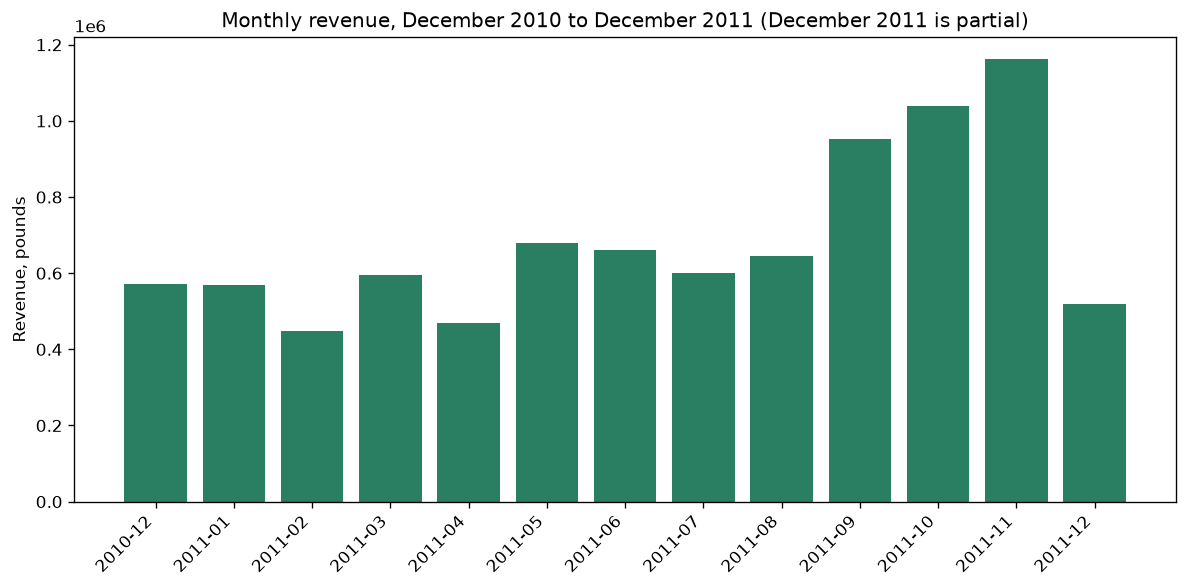

Best complete month: 2011-11 1161817.38
Quietest complete month: 2011-02 447137.35
Average complete month, pounds: 699434.59


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(monthly['month'], monthly['revenue'], color='#2a7f62')
ax.set_title('Monthly revenue, December 2010 to December 2011 (December 2011 is partial)')
ax.set_ylabel('Revenue, pounds')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '03_monthly_revenue.png')
plt.show()
complete = monthly[monthly['month'] != '2011-12']
print('Best complete month:', complete.loc[complete['revenue'].idxmax(), 'month'], round(complete['revenue'].max(), 2))
print('Quietest complete month:', complete.loc[complete['revenue'].idxmin(), 'month'], round(complete['revenue'].min(), 2))
print('Average complete month, pounds:', round(complete['revenue'].mean(), 2))

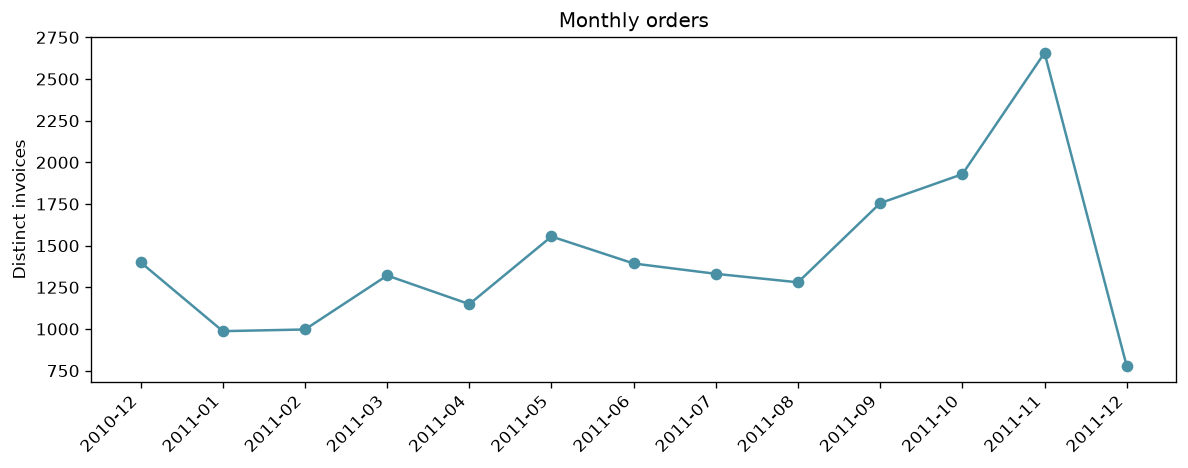

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly['month'], monthly['orders'], marker='o', color='#4a90a4')
ax.set_title('Monthly orders')
ax.set_ylabel('Distinct invoices')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '04_monthly_orders.png')
plt.show()

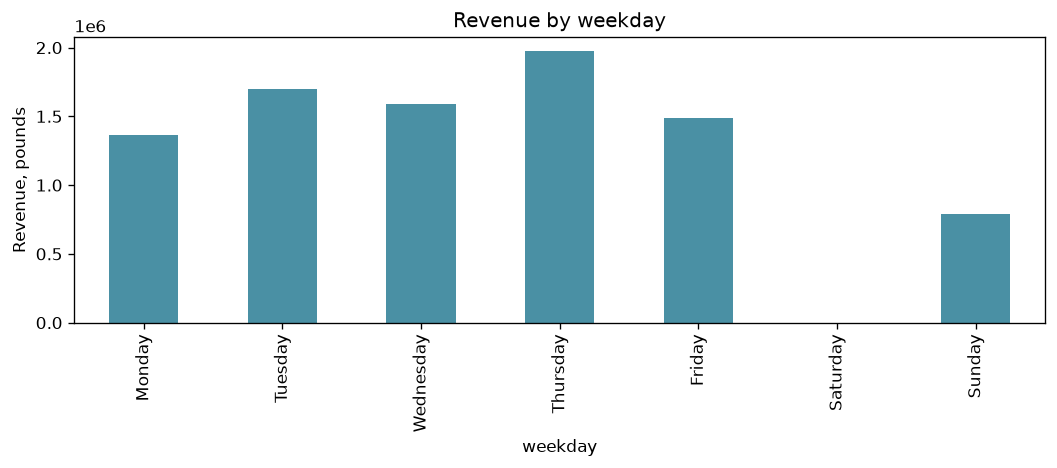

weekday
Monday       1367146.411
Tuesday      1700634.631
Wednesday    1588336.170
Thursday     1976859.070
Friday       1485917.401
Saturday             NaN
Sunday        792514.221


In [6]:
df['weekday'] = df['InvoiceDate'].dt.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
wd = df.groupby('weekday')['Revenue'].sum().reindex(order)
fig, ax = plt.subplots(figsize=(9, 4))
wd.plot(kind='bar', ax=ax, color='#4a90a4')
ax.set_title('Revenue by weekday')
ax.set_ylabel('Revenue, pounds')
plt.tight_layout()
plt.savefig(CHARTS / '05_weekday_revenue.png')
plt.show()
print(wd.to_string())

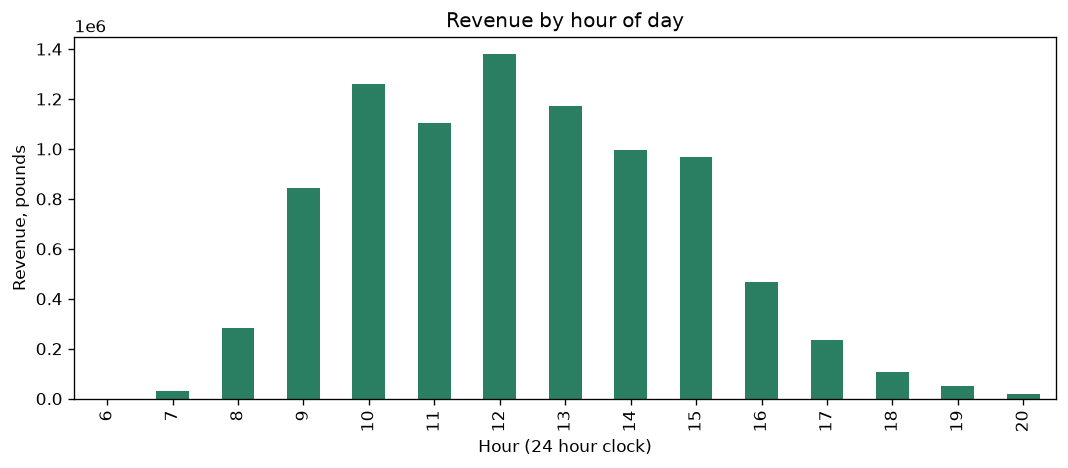

Busiest hour: 12 with 1378571.48 pounds.


In [7]:
df['hour'] = df['InvoiceDate'].dt.hour
hr = df.groupby('hour')['Revenue'].sum()
fig, ax = plt.subplots(figsize=(9, 4))
hr.plot(kind='bar', ax=ax, color='#2a7f62')
ax.set_title('Revenue by hour of day')
ax.set_ylabel('Revenue, pounds')
ax.set_xlabel('Hour (24 hour clock)')
plt.tight_layout()
plt.savefig(CHARTS / '06_hour_revenue.png')
plt.show()
print('Busiest hour:', hr.idxmax(), 'with', round(hr.max(), 2), 'pounds.')

## What we learned

November 2011 is the best complete month, at 1,161,817.38 pounds, followed by October 2011 at 1,039,318.79 pounds. February 2011 is the quietest complete month, at 447,137.35 pounds. That autumn rise fits a gift shop heading into the holiday season, but this data alone cannot prove the cause. It shows timing, not motive. The weekday chart shows Thursday as the strongest day, and midday as the busiest time, which is useful for staffing and for timing a message, not a promise of future sales.

Next: notebook 03 looks at which countries and products drive the money.